In [1]:
import sys, os; sys.path.append(os.path.join(os.path.dirname("2_siamese_errors.ipynb"), '..'))
from sklearn.metrics import confusion_matrix, accuracy_score
from siamese.dataset.data_loader import data_loader
from siamese.models.mobilenet_v3_large import model
from torchvision.io import read_image
import matplotlib.pyplot as plt
import numpy as np
import random
import torch
import json

In [ ]:
MODEL_PATH = "/home/tteuz/Desktop/mestrado/meta_pklot/dwell_time/pipeline/resources/siamese/PKLot/model_cnrparkext_plds_5c4be"
CONFIG_PATH = "/home/tteuz/Desktop/mestrado/meta_pklot/dwell_time/pipeline/resources/siamese/PKLot/model_cnrparkext_plds_5c4be"

MODEL_CONFIG = { "optimizer": "Adam", "device": "cuda:0" }

DATASET_CONFIG = {
        "train": [
            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/CNRParkEXT",
            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PLds"    
        ],
        "test": "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PKLot",
        "split": 0.7,
        "full_difficult": True,
        "img_size": [128, 128]
    }

In [ ]:
MODEL_PATH = "/home/tteuz/Desktop/mestrado/meta_pklot/dwell_time/pipeline/resources/siamese/CNRParkEXT/model_pklot_plds_01e83"
CONFIG_PATH = "/home/tteuz/Desktop/mestrado/meta_pklot/dwell_time/pipeline/resources/siamese/CNRParkEXT/model_pklot_plds_01e83"

MODEL_CONFIG = { "optimizer": "Adam", "device": "cuda:0" }

DATASET_CONFIG = {
        "train": [
            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PKLot",
            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PLds"    
        ],
        "test": "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/CNRParkEXT",
        "split": 0.7,
        "full_difficult": True,
        "img_size": [128, 128]
    }

In [2]:
MODEL_PATH = "/home/tteuz/Desktop/mestrado/meta_pklot/dwell_time/pipeline/resources/siamese/PLds/model_pklot_cnrparkext_2da05"
CONFIG_PATH = "/home/tteuz/Desktop/mestrado/meta_pklot/dwell_time/pipeline/resources/siamese/PLds/model_pklot_cnrparkext_2da05"

MODEL_CONFIG = { "optimizer": "Adam", "device": "cuda:0" }

DATASET_CONFIG = {
        "train": [
            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PKLot",
            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/CNRParkEXT"    
        ],
        "test": "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PLds",
        "split": 0.7,
        "full_difficult": True,
        "img_size": [128, 128]
    }

In [3]:
siamese_model = model(pre_trained=False, config=MODEL_CONFIG)
siamese_model.load_state_dict(torch.load(f"{MODEL_PATH}.pt", map_location="cuda:0"))

siamese_json = json.load(open(f"{CONFIG_PATH}.json", "r"))
threshold = siamese_json["metrics"]["threshold"]

In [4]:
ds_loader = data_loader(DATASET_CONFIG)
test_subsets = ds_loader.get_test_subsets()

In [5]:
wrong_pairs = {}
final_cm = [[0, 0], [0, 0]]
for key, subset in test_subsets.items():
    test_loader = torch.utils.data.DataLoader(subset, batch_size=1000, shuffle=False, num_workers=8, pin_memory=True)
    preds, labels = siamese_model.predict(test_loader, threshold)
    np_preds, np_labels = np.array(preds), np.array(labels)

    indexes = np.where(np_preds != np_labels)[0]
    indexes = [(index, np_labels[index]) for index in indexes]
    wrong_pairs[key] = [(index[1], subset.images[index[0]]) for index in indexes]

    accuracy = accuracy_score(labels, preds)
    cm = confusion_matrix(labels, preds)
    final_cm += cm

    print(f"{key}: acc: {accuracy}")
print(f"\nTotal: {np.trace(final_cm) / np.sum(final_cm)}")

QRIDR: acc: 0.8428571428571429
ISSHK: acc: 0.8625
VXUSD: acc: 0.9375
VMLIX: acc: 0.8382352941176471

Total: 0.8545258620689655


20 2
QRIDR
     Falso positivo:


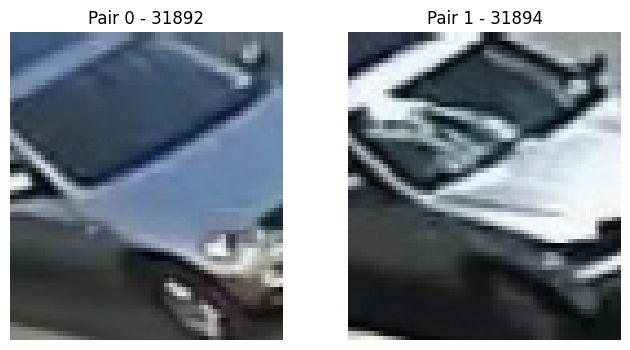

     Falso negativo:


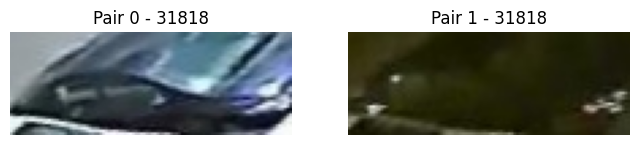

49 6
ISSHK
     Falso positivo:


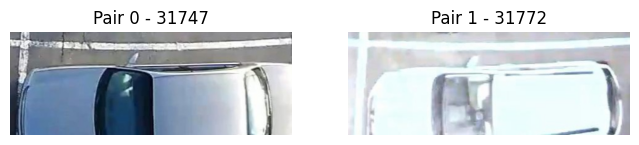

     Falso negativo:


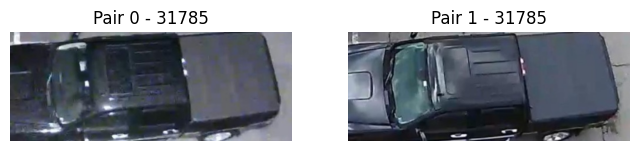

3 0
VXUSD
     Falso positivo:
     Falso negativo:


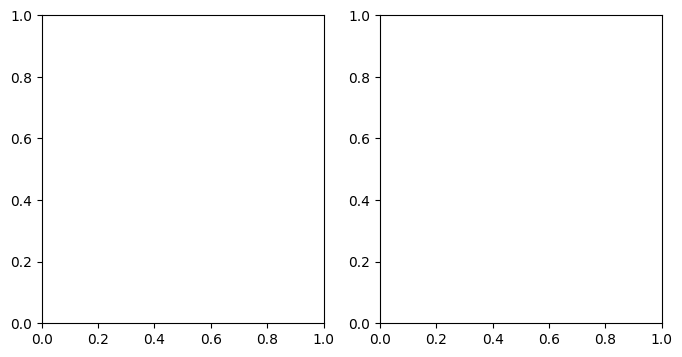

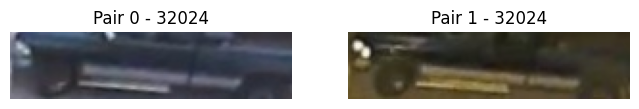

49 6
VMLIX
     Falso positivo:


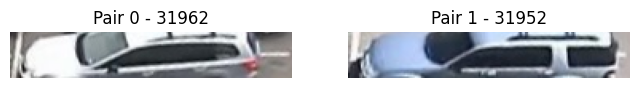

     Falso negativo:


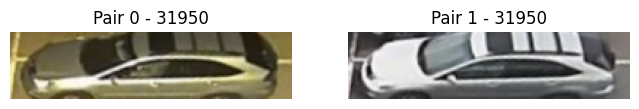

In [10]:
def tensor_to_numpy(tensor):
    return tensor.permute(1, 2, 0).cpu().numpy()

for subset, wrongs in wrong_pairs.items():
    false_positives = [wrong for wrong in wrongs if wrong[0] == 1]
    false_negatives = [wrong for wrong in wrongs if wrong[0] == 0]
    print(len(false_negatives), len(false_positives))

    print(subset)

    print("     Falso positivo:")
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    if len(false_positives) > 1:

        pair = random.choice(false_positives)[1]

        pair_0 = read_image(pair[0]).float() / 255.0
        pair_1 = read_image(pair[1]).float() / 255.0

        axes[0].imshow(tensor_to_numpy(pair_0))
        axes[0].set_title(f"Pair 0 - {pair[0].split('#')[-1].replace('.jpg', '')}")
        axes[0].axis("off")

        axes[1].imshow(tensor_to_numpy(pair_1))
        axes[1].set_title(f"Pair 1 - {pair[1].split('#')[-1].replace('.jpg', '')}")
        axes[1].axis("off")

        plt.show()

    print("     Falso negativo:")
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    if len(false_negatives) > 1:
        pair = random.choice(false_negatives)[1]

        pair_0 = read_image(pair[0]).float() / 255.0
        pair_1 = read_image(pair[1]).float() / 255.0

        axes[0].imshow(tensor_to_numpy(pair_0))
        axes[0].set_title(f"Pair 0 - {pair[0].split('#')[-1].replace('.jpg', '')}")
        axes[0].axis("off")

        axes[1].imshow(tensor_to_numpy(pair_1))
        axes[1].set_title(f"Pair 1 - {pair[1].split('#')[-1].replace('.jpg', '')}")
        axes[1].axis("off")

        plt.show()
    